# FRED-MD full joint-CV search

This notebook uses the package-level `weighted_erm_joint_cv` after its loss
semantics were corrected. For every configuration below, WERM segmentation
and hard segment refits use the base loss M. Absolute loss is used only for
held-out CV scoring.

Every surface is exhaustive over both the coefficient-penalty constant and
0--4 candidate change points. Loss, penalty norm, fold count, and minimum
spacing are treated as sensitivity configurations; they are declared before
looking at results. All outcomes are retained, including configurations that
select zero, one, or four change points.

In [1]:
from pathlib import Path
import hashlib
import itertools
import json
import os
import pickle
import platform
import sys
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from WERM.experiment_utils import weighted_erm_joint_cv

ROOT = Path.cwd()
DATA_PATH = ROOT / "FRED-MD data" / "fredmd_data.pkl"
RESULT_DIR = ROOT / "results" / "FRED-MD_full-joint-cv-search"
FIGURE_DIR = ROOT / "figures" / "FRED-MD_full-joint-cv-search"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT = RESULT_DIR / "checkpoint.json"
SUMMARY_PATH = RESULT_DIR / "summary.json"
N_JOBS = min(36, os.cpu_count() or 1)

print({
    "python": sys.version.split()[0], "platform": platform.platform(),
    "jax": jax.__version__, "n_jobs": N_JOBS,
})

{'python': '3.10.18', 'platform': 'Linux-6.11.0-29-generic-x86_64-with-glibc2.39', 'jax': '0.4.35', 'n_jobs': 36}


In [2]:
with DATA_PATH.open("rb") as handle:
    fred = pickle.load(handle)

X = np.asarray(fred["X"], dtype=float)
y = np.asarray(fred["y"], dtype=float).reshape(-1)
dates = np.asarray(fred["date"]).astype(str).reshape(-1)
n, p = X.shape
assert X.shape == (773, 114) and y.shape == (773,)

DATA_HASH = hashlib.blake2b(
    np.ascontiguousarray(X).tobytes() + np.ascontiguousarray(y).tobytes(),
    digest_size=16,
).hexdigest()
REFERENCE_DATES = {
    "McScan": ["1974-02", "2010-05", "2019-05"],
    "DPDU_different_window": ["2008-06", "2020-01"],
}
REFERENCE_INDICES = {
    name: [int(np.flatnonzero(dates == value)[0]) for value in values]
    for name, values in REFERENCE_DATES.items()
}

def squared_loss(prediction, truth):
    return jnp.square(prediction - truth)

def absolute_loss(prediction, truth):
    return jnp.abs(prediction - truth)

def make_huber(epsilon):
    epsilon = float(epsilon)
    def huber_loss(prediction, truth):
        residual = prediction - truth
        absolute = jnp.abs(residual)
        return jnp.where(
            absolute <= epsilon,
            0.5 * jnp.square(residual),
            epsilon * (absolute - 0.5 * epsilon),
        )
    return huber_loss

LOSSES = {
    "least-squares": squared_loss,
    "Huber-eps0.5": make_huber(0.5),
    "Huber-eps0.75": make_huber(0.75),
    "Huber-eps1": make_huber(1.0),
    "Huber-eps1.35": make_huber(1.35),
    "Huber-eps2": make_huber(2.0),
}

## Predeclared exhaustive grid

The constant grid spans weak through strong regularization and is shared by
L1 and L2 for a transparent comparison. Each surface contains 30 candidates:
five segment counts times six constants. Two-fold CV is evaluated across a
broad spacing grid; three- and five-fold CV are evaluated at the central
spacing choice to check fold sensitivity. Huber epsilon 1.35 is part of that
primary grid. Epsilon values 0.5, 0.75, 1.0, and 2.0 are predeclared
sensitivities at two folds and the two central spacing choices. The response
standard deviation is about 0.88, so these thresholds span strongly robust
through nearly least-squares behavior on the actual fitted scale.

In [3]:
CONSTANTS = (0.15, 0.3, 0.5, 0.75, 1.0, 2.0)
SEGMENT_COUNTS = (1, 2, 3, 4, 5)  # 0--4 change points
SEARCH_CONFIGS = []
for loss_name, penalty_norm in itertools.product(
    ("least-squares", "Huber-eps1.35"), ("l1", "l2")
):
    for delta_fraction in (1/50, 1/40, 1/30, 1/25, 1/20):
        SEARCH_CONFIGS.append({
            "loss": loss_name, "penalty_norm": penalty_norm,
            "num_folds": 2, "delta_fraction": delta_fraction,
        })
    for num_folds in (3, 5):
        SEARCH_CONFIGS.append({
            "loss": loss_name, "penalty_norm": penalty_norm,
            "num_folds": num_folds, "delta_fraction": 1/40,
        })

for loss_name, penalty_norm, delta_fraction in itertools.product(
    ("Huber-eps0.5", "Huber-eps0.75", "Huber-eps1", "Huber-eps2"),
    ("l1", "l2"), (1/40, 1/30),
):
    SEARCH_CONFIGS.append({
        "loss": loss_name, "penalty_norm": penalty_norm,
        "num_folds": 2, "delta_fraction": delta_fraction,
    })

assert len(SEARCH_CONFIGS) == 44
pd.DataFrame(SEARCH_CONFIGS)

,loss,penalty_norm,num_folds,delta_fraction
0,least-squares,l1,2,0.020000
1,least-squares,l1,2,0.025000
2,least-squares,l1,2,0.033333
3,least-squares,l1,2,0.040000
4,least-squares,l1,2,0.050000
5,least-squares,l1,3,0.025000
6,least-squares,l1,5,0.025000
7,least-squares,l2,2,0.020000
8,least-squares,l2,2,0.025000
9,least-squares,l2,2,0.033333


In [4]:
def config_key(config):
    return "|".join([
        config["loss"], config["penalty_norm"],
        str(config["num_folds"]), f'{config["delta_fraction"]:.12g}',
    ])

def alignment(cp):
    cp = tuple(int(value) for value in cp)
    candidates = []
    if len(cp) == 3:
        target = REFERENCE_INDICES["McScan"]
        distances = [abs(a - b) for a, b in zip(cp, target)]
        candidates.append(("McScan", distances))
    if len(cp) == 2:
        target = REFERENCE_INDICES["DPDU_different_window"]
        candidates.append(("DPDU_different_window", [abs(a - b) for a, b in zip(cp, target)]))
        for subset in itertools.combinations(REFERENCE_INDICES["McScan"], 2):
            candidates.append(("McScan_best_2_of_3", [abs(a - b) for a, b in zip(cp, subset)]))
    if not candidates:
        return {"reference": None, "distances_months": [], "mean_months": None, "max_months": None}
    reference, distances = min(candidates, key=lambda item: (np.mean(item[1]), max(item[1])))
    return {
        "reference": reference,
        "distances_months": [int(value) for value in distances],
        "mean_months": float(np.mean(distances)),
        "max_months": int(max(distances)),
    }

if CHECKPOINT.exists():
    with CHECKPOINT.open() as handle:
        records = json.load(handle)
else:
    records = []
completed = {record["config_key"] for record in records}
print(f"Resuming with {len(records)} of {len(SEARCH_CONFIGS)} configurations complete")

Resuming with 9 of 44 configurations complete


In [5]:
for setting_index, config in enumerate(SEARCH_CONFIGS, start=1):
    key = config_key(config)
    if key in completed:
        continue
    print(f'[{setting_index}/{len(SEARCH_CONFIGS)}] {key}', flush=True)
    started = time.perf_counter()
    selected, cp, diagnostics = weighted_erm_joint_cv(
        X=X, y=y, M=LOSSES[config["loss"]], M_scorer=absolute_loss,
        Lmax=max(SEGMENT_COUNTS), delta_fraction=config["delta_fraction"],
        l1_constants=CONSTANTS, num_folds=config["num_folds"],
        n_jobs=N_JOBS, standardize_y=False,
        selection_strategy="exhaustive", return_diagnostics=True,
        penalty_norm=config["penalty_norm"], segment_counts=SEGMENT_COUNTS,
    )
    candidates = [tuple(value) for value in diagnostics["candidates"]]
    scores = np.asarray(diagnostics["scores"], dtype=float)
    chosen_index = candidates.index(tuple(selected))
    baseline = min(
        score for candidate, score in zip(candidates, scores)
        if candidate[0] == 1 and np.isfinite(score)
    )
    selected_score = float(scores[chosen_index])
    cp = np.asarray(cp, dtype=int).reshape(-1)
    record = {
        **config, "config_key": key,
        "constants": list(CONSTANTS), "segment_counts": list(SEGMENT_COUNTS),
        "score_loss": "absolute_loss", "refit_loss": config["loss"],
        "selected_segments": int(selected[0]),
        "selected_change_points": int(selected[0] - 1),
        "selected_constant": float(selected[1]),
        "estimated_change_points": cp.tolist(),
        "estimated_dates": dates[cp].tolist(),
        "selected_cv_mean": selected_score / n,
        "best_zero_cp_cv_mean": float(baseline / n),
        "relative_improvement_vs_zero_pct": float((baseline - selected_score) / baseline * 100),
        "alignment": alignment(cp),
        "candidate_scores": [
            {"segments": int(candidate[0]), "change_points": int(candidate[0] - 1),
             "constant": float(candidate[1]), "cv_total": float(score), "cv_mean": float(score / n)}
            for candidate, score in zip(candidates, scores)
        ],
        "elapsed_seconds": time.perf_counter() - started,
    }
    records.append(record)
    completed.add(key)
    with CHECKPOINT.open("w") as handle:
        json.dump(records, handle, indent=2)
    print({k: record[k] for k in (
        "selected_change_points", "selected_constant", "estimated_dates",
        "relative_improvement_vs_zero_pct", "elapsed_seconds",
    )}, flush=True)

assert len(records) == len(SEARCH_CONFIGS)

[10/44] least-squares|l2|2|0.0333333333333


\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 2, Lmax: 2


100%|██████████| 1/1 [00:00<00:00, 988.52it/s]

100%|██████████| 1/1 [00:00<00:00, 1467.57it/s]


\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 1, Lmax: 1
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 4, Lmax: 4
\Delta: 1, n: 50, Lmin: 2, Lmax: 2
\Delta: 1, n: 50, Lmin: 5, Lmax: 5
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 3, Lmax: 3
\Delta: 1, n: 50, Lmin: 5, Lmax: 5


  0%|          | 0/1 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

100%|██████████| 1/1 [00:00<00:00,  6.56it/s]

  0%|          | 0/1128 [00:00<?, ?it/s]An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
100%|██████████| 1/1 [00:00<00:00, 104.47it/s]

  0%|          | 0/194580 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00,  5.92it/s]

100%|██████████| 1/1 [00:00<00:00,  6.21it/s]

100%|██████████| 1/1 [00:00<00:00,  6.54it/s]

  9%|▉         | 17263/194580 [00:00<00:02, 86576.44it/s]

... (2,996 outputs left out)

\Delta: 1, n: 50, Lmin: 1, Lmax: 1


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{'selected_change_points': 0, 'selected_constant': 0.3, 'estimated_dates': [], 'relative_improvement_vs_zero_pct': 0.0, 'elapsed_seconds': 14.614517892710865}


In [6]:
result_table = pd.DataFrame([{
    "loss": record["loss"], "penalty": record["penalty_norm"],
    "folds": record["num_folds"], "delta": record["delta_fraction"],
    "selected CPs": record["selected_change_points"],
    "C": record["selected_constant"], "dates": ";".join(record["estimated_dates"]),
    "CV improvement vs zero (%)": record["relative_improvement_vs_zero_pct"],
    "reference": record["alignment"]["reference"],
    "mean reference distance (months)": record["alignment"]["mean_months"],
    "max reference distance (months)": record["alignment"]["max_months"],
} for record in records])

target_table = result_table[result_table["selected CPs"].isin([2, 3])].copy()
target_table = target_table.sort_values(
    ["mean reference distance (months)", "CV improvement vs zero (%)"],
    ascending=[True, False], na_position="last",
)
target_table.head(20)

,loss,penalty,folds,delta,selected CPs,C,dates,CV improvement vs zero (%),reference,mean reference distance (months),max reference distance (months)
17,Huber-eps1.35,l1,2,0.040000,3,0.3,1972-11;2009-06;2015-03,0.130222,McScan,25.333333,50.0
14,Huber-eps1.35,l1,2,0.020000,3,0.3,1972-11;2009-06;2010-10,0.221842,McScan,43.000000,103.0
16,Huber-eps1.35,l1,2,0.033333,2,0.3,1983-01;2009-06,0.405306,McScan_best_2_of_3,59.000000,107.0
18,Huber-eps1.35,l1,2,0.050000,2,0.3,1983-01;2009-06,0.309629,McScan_best_2_of_3,59.000000,107.0
15,Huber-eps1.35,l1,2,0.025000,2,0.3,1983-01;2009-06,0.233855,McScan_best_2_of_3,59.000000,107.0


In [7]:
summary = {
    "notebook": "FRED-MD Full CV Search.ipynb",
    "data_hash": DATA_HASH,
    "loss_contract": {
        "segmentation": "base loss M",
        "hard_segment_refits": "base loss M",
        "heldout_scoring_only": "absolute_loss",
    },
    "grid": {
        "constants": list(CONSTANTS), "segment_counts": list(SEGMENT_COUNTS),
        "configuration_count": len(SEARCH_CONFIGS),
        "selection_strategy": "exhaustive",
    },
    "reference_dates": REFERENCE_DATES,
    "records": records,
    "target_records": [
        record for record in records if record["selected_change_points"] in (2, 3)
    ],
}
with SUMMARY_PATH.open("w") as handle:
    json.dump(summary, handle, indent=2)
result_table.to_csv(RESULT_DIR / "all_configurations.csv", index=False)
target_table.to_csv(RESULT_DIR / "two_or_three_change_points.csv", index=False)

counts = result_table.groupby(["loss", "penalty", "selected CPs"]).size().unstack(fill_value=0)
display(counts)
print(f"Found {len(target_table)} configurations selecting 2 or 3 change points")
display(target_table.head(20))

selected CPs           0  1  2  3
loss          penalty            
Huber-eps0.5  l1       0  2  0  0
              l2       2  0  0  0
Huber-eps0.75 l1       0  2  0  0
              l2       2  0  0  0
Huber-eps1    l1       0  2  0  0
              l2       2  0  0  0
Huber-eps1.35 l1       1  1  3  2
              l2       7  0  0  0
Huber-eps2    l1       0  2  0  0
              l2       2  0  0  0
least-squares l1       2  5  0  0
              l2       7  0  0  0

Found 5 configurations selecting 2 or 3 change points


,loss,penalty,folds,delta,selected CPs,C,dates,CV improvement vs zero (%),reference,mean reference distance (months),max reference distance (months)
17,Huber-eps1.35,l1,2,0.040000,3,0.3,1972-11;2009-06;2015-03,0.130222,McScan,25.333333,50.0
14,Huber-eps1.35,l1,2,0.020000,3,0.3,1972-11;2009-06;2010-10,0.221842,McScan,43.000000,103.0
16,Huber-eps1.35,l1,2,0.033333,2,0.3,1983-01;2009-06,0.405306,McScan_best_2_of_3,59.000000,107.0
18,Huber-eps1.35,l1,2,0.050000,2,0.3,1983-01;2009-06,0.309629,McScan_best_2_of_3,59.000000,107.0
15,Huber-eps1.35,l1,2,0.025000,2,0.3,1983-01;2009-06,0.233855,McScan_best_2_of_3,59.000000,107.0


BEST PREDECLARED REFERENCE-ALIGNED 2/3-CP CONFIGURATION
{
  "loss": "Huber-eps1.35",
  "penalty_norm": "l1",
  "num_folds": 2,
  "delta_fraction": 0.04,
  "selected_change_points": 3,
  "selected_constant": 0.3,
  "estimated_change_points": [
    154,
    593,
    662
  ],
  "estimated_dates": [
    "1972-11",
    "2009-06",
    "2015-03"
  ],
  "selected_cv_mean": 0.5377880210673297,
  "best_zero_cp_cv_mean": 0.5384892550038032,
  "relative_improvement_vs_zero_pct": 0.13022245661494677,
  "alignment": {
    "reference": "McScan",
    "distances_months": [
      15,
      11,
      50
    ],
    "mean_months": 25.333333333333332,
    "max_months": 50
  }
}


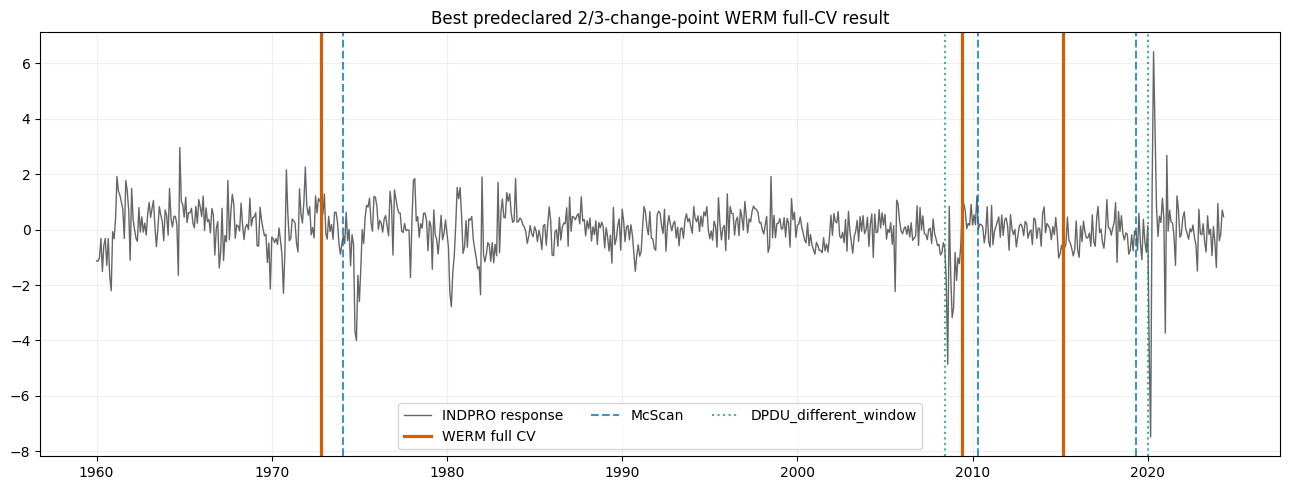

In [8]:
if len(target_table):
    best_row = target_table.iloc[0]
    best_record = next(
        record for record in records
        if record["loss"] == best_row["loss"]
        and record["penalty_norm"] == best_row["penalty"]
        and record["num_folds"] == int(best_row["folds"])
        and np.isclose(record["delta_fraction"], best_row["delta"])
    )
    print("BEST PREDECLARED REFERENCE-ALIGNED 2/3-CP CONFIGURATION")
    print(json.dumps({key: best_record[key] for key in (
        "loss", "penalty_norm", "num_folds", "delta_fraction",
        "selected_change_points", "selected_constant",
        "estimated_change_points", "estimated_dates",
        "selected_cv_mean", "best_zero_cp_cv_mean",
        "relative_improvement_vs_zero_pct", "alignment",
    )}, indent=2))

    figure, axis = plt.subplots(figsize=(13, 5))
    axis.plot(pd.to_datetime(dates), y, color="0.4", linewidth=1.0, label="INDPRO response")
    for index, value in enumerate(best_record["estimated_change_points"]):
        axis.axvline(pd.Timestamp(str(dates[value])), color="#D55E00", linewidth=2.3,
                     label="WERM full CV" if index == 0 else None)
    for name, color, style in (("McScan", "#0072B2", "--"), ("DPDU_different_window", "#009E73", ":")):
        for index, value in enumerate(REFERENCE_INDICES[name]):
            axis.axvline(pd.Timestamp(str(dates[value])), color=color, linestyle=style, alpha=0.75,
                         label=name if index == 0 else None)
    axis.set_title("Best predeclared 2/3-change-point WERM full-CV result")
    axis.grid(alpha=0.2)
    axis.legend(ncol=3)
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / "best_reference_aligned_result.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No predeclared configuration selected exactly 2 or 3 change points.")